# I will use transfer learning for for this project

first I will train a CNN from strach on ESC50 Data and then freeze the parameters and then will train on GENRES_STEMS Data

In [1]:
from helper.golbal_variables import *

In [2]:
import torch, torchaudio, numpy
print(torch.__version__)
print(torchaudio.__version__)
print(numpy.__version__)

2.2.2+cpu
2.2.2+cpu
1.26.4


## Exploring EC50 data

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import IPython.display as ipd

In [4]:
esc50_df = pd.read_csv(ESC_50_MASTER/"meta/esc50.csv")

Files follow a specific pattern: {FOLD}-{CLIP_ID}-{TAKE}-{TARGET}.wav. The TARGET (0-49) is the class ID you are trying to predict.

In [5]:
esc50_df.shape

(2000, 7)

In [6]:
esc50_df.head()

,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


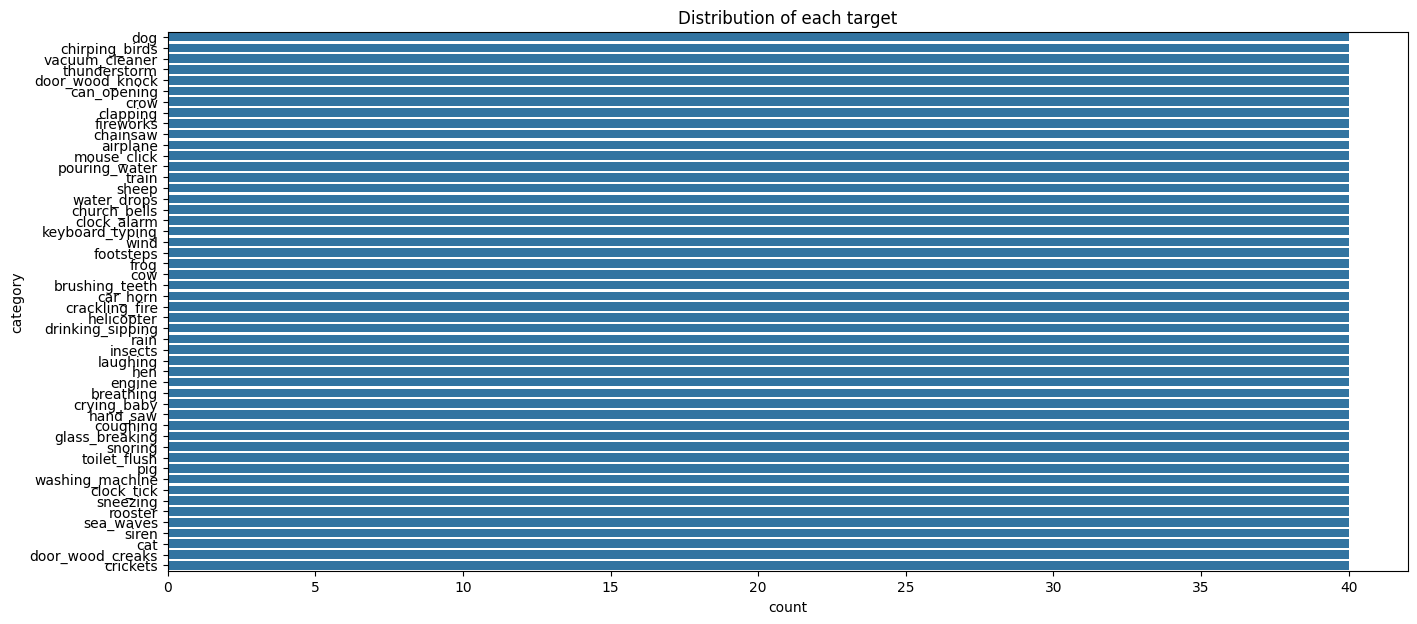

In [7]:
plt.figure(figsize=(16, 7))
sns.countplot(data=esc50_df, y="category")
plt.title("Distribution of each target")
plt.show()

All category have same distribution our data of ECS50 is balanced

## Checking wave forms

### Checking genres

In [2]:
from pathlib import Path
import librosa
import librosa.display
import matplotlib.pyplot as plt
import IPython.display as ipd
from IPython.display import display

def plot_each_wav(folder: Path):
    files = list(folder.glob("*.wav")) 
    
    if not files:
        print(f"No .wav files found in {folder}")
        return

    fig, axes = plt.subplots(len(files), 1, figsize=(14, 3 * len(files)), squeeze=False)
    axes = axes.flatten()

    for ax, filename in zip(axes, files):
        data, sample_rate = librosa.load(filename, sr=None)
        librosa.display.waveshow(data, sr=sample_rate, ax=ax)
        
        ax.set_title(filename.name)
        ax.set_xlabel("Time (seconds)")
        ax.set_ylabel("Amplitude")

    plt.tight_layout()
    plt.show()

    print("\nAudio Samples:\n")
    for filename in files:
        print(filename.name)
        display(ipd.Audio(str(filename)))
        print("-" * 60)

### BLUES

In [ ]:
# plot_each_wav(BLUES / "blues.00000")

### classical

In [ ]:
# plot_each_wav(CLASSICAL / "classical.00000")

## 

# Now let's train a model on ESC50 dataset

In [2]:
import torch
from helper.DataLoaders.dataloader_with_preprocessed import GenreDataLoader, collate_fn_chunks
from torch.utils.data import DataLoader

from CNN_model.cnn_arch_for_esc50 import ESC50_CNN
from CNN_model.utils import cross_validation, train, test

import matplotlib.pyplot as plt
import librosa.display
from IPython.display import display
import IPython.display as ipd

### Checking if DataLoader is laoding data properly

In [ ]:
# dataset = ESC50_DataLoader(ESC_50_MASTER)
# dataset.load_meta_data(ESC_50_MASTER/"meta/esc50.csv")

# loader = DataLoader(dataset, batch_size=16, shuffle=True)

# for x, y in loader:
#     print(x.shape)
#     print(y.shape)
#     break

Loading metadata from file: data\ESC-50-master\meta\esc50.csv
torch.Size([16, 1, 256, 431])
torch.Size([16])


z:\dlgen-AI-project\.venv\Lib\site-packages\torchaudio\functional\functional.py:584: UserWarning: At least one mel filterbank has all zero values. The value for `n_mels` (256) may be set too high. Or, the value for `n_freqs` (513) may be set too low.
  warnings.warn(


Checking if loader if giving correct spectrum

In [ ]:
# import matplotlib.pyplot as plt
# import librosa.display
# import torchaudio
# from IPython.display import display
# import IPython.display as ipd

# def load_spectrum_waveform_foresc50(index):
#     mel, label = dataset[index]
#     mel = mel[0].detach().cpu().numpy()

#     row = dataset.meta_data.iloc[index]
#     file_path = dataset.audio_dir / row["filename"]

#     waveform, sr = torchaudio.load(file_path)

#     waveform = waveform.mean(dim=0)

#     if sr != 22050:
#         resampler = torchaudio.transforms.Resample(sr, 22050)
#         waveform = resampler(waveform.unsqueeze(0)).squeeze(0)

#     wave_np = waveform.detach().cpu().numpy()

#     fig, axes = plt.subplots(2, 1, figsize=(12, 8))

#     # WAVEFORM
#     axes[0].plot(wave_np)
#     axes[0].set_title("Waveform (Time Domain)")
#     axes[0].set_xlabel("Samples")
#     axes[0].set_ylabel("Amplitude")

#     # MEL
#     img = librosa.display.specshow(
#         mel,
#         sr=22050,
#         hop_length=512,
#         x_axis="time",
#         y_axis="mel",
#         ax=axes[1]
#     )

#     axes[1].set_title(f"Mel Spectrogram | Label: {label.item()}")
#     fig.colorbar(img, ax=axes[1], format="%+2.0f dB")

#     plt.tight_layout()
#     plt.show()

#     display(ipd.Audio(str(file_path)))

In [ ]:
# load_spectrum_waveform_foresc50(index=99)

### Now let's train our model on ESC50 dataset

In [3]:
from collections import Counter
from torch.utils.data import DataLoader

# Load your training dataset
dataset = GenreDataLoader(root_dir=GENRES_STEMS)

# Count samples per genre
genre_counts = Counter(dataset.labels)
genre_names = {v: k for k, v in dataset.class_map.items()}

print("Current Distribution:")
for genre_idx, count in sorted(genre_counts.items()):
    genre_name = genre_names[genre_idx]
    print(f"  {genre_name}: {count} songs")

print(f"\nTotal: {len(dataset)} songs")
print(f"Min: {min(genre_counts.values())}, Max: {max(genre_counts.values())}")
print(f"Imbalance ratio: {max(genre_counts.values()) / min(genre_counts.values()):.2f}x")

z:\dlgen-AI-project\.venv\Lib\site-packages\torchaudio\functional\functional.py:584: UserWarning: At least one mel filterbank has all zero values. The value for `n_mels` (256) may be set too high. Or, the value for `n_freqs` (513) may be set too low.
  warnings.warn(


Classes: {'blues': 0, 'classical': 1, 'country': 2, 'disco': 3, 'hiphop': 4, 'jazz': 5, 'metal': 6, 'pop': 7, 'reggae': 8, 'rock': 9}
Total songs: 1000
Current Distribution:
  blues: 100 songs
  classical: 100 songs
  country: 100 songs
  disco: 100 songs
  hiphop: 100 songs
  jazz: 100 songs
  metal: 100 songs
  pop: 100 songs
  reggae: 100 songs
  rock: 100 songs

Total: 1000 songs
Min: 100, Max: 100
Imbalance ratio: 1.00x


In [4]:
dataloader = DataLoader(
    dataset=dataset,
    shuffle=False,
    collate_fn=collate_fn_chunks,
    batch_size=16
)

In [ ]:
# model = ESC50_CNN()

# device = 'cuda' if torch.cuda.is_available() else 'cpu'

# cross_validation(
#     model=model,
#     esc50_dir = ESC_50_MASTER,
#     meta_csv = ESC_50_MASTER/"meta/esc50.csv",
#     device=device,
#     epochs=25,
#     batch_size=128,
#     fold=5
# )

# dfs